# Emotion  Detection using CNN + Transfer Learning (vgg16)


Imports


In [1]:

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt

In [2]:
import keras
import tensorflow as tf

from keras.models import Sequential
from keras.layers import Dropout,BatchNormalization,Dense,Conv2D,MaxPooling2D,Flatten,GlobalAveragePooling2D
from keras.optimizers import Adam
from keras.callbacks import EarlyStopping
from keras import layers
from keras.layers import Input
from keras.applications.vgg16 import VGG16,preprocess_input

In [3]:
!kaggle datasets download -d dollyprajapati182/balanced-raf-db-dataset-7575-grayscale

Dataset URL: https://www.kaggle.com/datasets/dollyprajapati182/balanced-raf-db-dataset-7575-grayscale
License(s): unknown
100% 124M/124M [00:02<00:00, 62.6MB/s]



Downloading and preparing the dataset

In [4]:
!mkdir -p dataset_emotion_detection
!unzip -q /content/balanced-raf-db-dataset-7575-grayscale.zip -d /content/dataset_emotion_detection

In [5]:
train_ds=keras.utils.image_dataset_from_directory(
    directory='/content/dataset_emotion_detection/train',
    labels='inferred',
    label_mode='categorical',
    batch_size=32,
    image_size=(224,224),
    shuffle=True
)

Found 30023 files belonging to 7 classes.


In [6]:
val_ds=keras.utils.image_dataset_from_directory(
    directory='/content/dataset_emotion_detection/val',
    labels='inferred',
    label_mode='categorical',
    batch_size=32,
   image_size=(224,224),
    shuffle=False,

)

Found 7504 files belonging to 7 classes.


In [7]:
test_ds=keras.utils.image_dataset_from_directory(
    directory='/content/dataset_emotion_detection/test',
    labels='inferred',
    label_mode='categorical',
    image_size=(224,224),
    shuffle=False,
    batch_size=32

)

Found 4165 files belonging to 7 classes.


In [8]:
def process(image,label):

  image=preprocess_input(image)
  return image,label

train_ds=train_ds.map(process)
test_ds=test_ds.map(process)
val_ds=val_ds.map(process)

Using feature extraction transfer learning method.We have used here vgg16


In [9]:
conv_base=VGG16(
    weights='imagenet',
    input_shape=(224,224,3),
    include_top=False
)

58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [10]:
conv_base.trainable=False

Preparing and training the model

In [11]:

model=Sequential()

model.add(Input(shape=(224, 224, 3)))
model.add(conv_base)

model.add(GlobalAveragePooling2D())

model.add(Dense(256,activation='relu'))
model.add(Dropout(0.3))

model.add(Dense(256,activation='relu'))
model.add(Dropout(0.5))

model.add(Dense(128,activation='relu'))
model.add(Dropout(0.3))

model.add(Dense(7,activation='softmax'))


In [12]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ vgg16 (Functional)              │ (None, 7, 7, 512)      │    14,714,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 512)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 256)            │        65,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 7)              │           903 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,945,607 (57.01 MB)

 Trainable params: 230,919 (902.03 KB)

 Non-trainable params: 14,714,688 (56.13 MB)

In [13]:
model.compile(metrics=['accuracy'],loss='categorical_crossentropy',optimizer=Adam(learning_rate=0.001))

In [14]:
history=model.fit(train_ds,validation_data=val_ds,epochs=20,callbacks=[EarlyStopping(restore_best_weights=True,monitor='val_loss',patience=3)])

Epoch 1/20
939/939 ━━━━━━━━━━━━━━━━━━━━ 223s 214ms/step - accuracy: 0.3252 - loss: 1.7440 - val_accuracy: 0.4566 - val_loss: 1.4422
Epoch 2/20
939/939 ━━━━━━━━━━━━━━━━━━━━ 210s 224ms/step - accuracy: 0.4501 - loss: 1.4563 - val_accuracy: 0.5300 - val_loss: 1.2777
Epoch 3/20
939/939 ━━━━━━━━━━━━━━━━━━━━ 213s 226ms/step - accuracy: 0.5002 - loss: 1.3401 - val_accuracy: 0.5628 - val_loss: 1.1936
Epoch 4/20
939/939 ━━━━━━━━━━━━━━━━━━━━ 213s 227ms/step - accuracy: 0.5348 - loss: 1.2545 - val_accuracy: 0.5928 - val_loss: 1.1235
Epoch 5/20
939/939 ━━━━━━━━━━━━━━━━━━━━ 213s 227ms/step - accuracy: 0.5659 - loss: 1.1853 - val_accuracy: 0.6109 - val_loss: 1.0623
Epoch 6/20
939/939 ━━━━━━━━━━━━━━━━━━━━ 212s 226ms/step - accuracy: 0.5842 - loss: 1.1375 - val_accuracy: 0.6193 - val_loss: 1.0410
Epoch 7/20
939/939 ━━━━━━━━━━━━━━━━━━━━ 212s 226ms/step - accuracy: 0.6050 - loss: 1.0852 - val_accuracy: 0.6525 - val_loss: 0.9776
Epoch 8/20
939/939 ━━━━━━━━━━━━━━━━━━━━ 213s 227ms/step - accuracy: 0.6208 -

In [15]:
history_continued = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=30,
    initial_epoch=20,
    callbacks=[EarlyStopping(restore_best_weights=True, monitor='val_loss', patience=3)]
)

Epoch 21/30
939/939 ━━━━━━━━━━━━━━━━━━━━ 213s 226ms/step - accuracy: 0.7146 - loss: 0.8023 - val_accuracy: 0.7219 - val_loss: 0.7954
Epoch 22/30
939/939 ━━━━━━━━━━━━━━━━━━━━ 212s 226ms/step - accuracy: 0.7148 - loss: 0.7975 - val_accuracy: 0.7186 - val_loss: 0.8010
Epoch 23/30
939/939 ━━━━━━━━━━━━━━━━━━━━ 213s 227ms/step - accuracy: 0.7250 - loss: 0.7770 - val_accuracy: 0.7199 - val_loss: 0.7953
Epoch 24/30
939/939 ━━━━━━━━━━━━━━━━━━━━ 213s 226ms/step - accuracy: 0.7236 - loss: 0.7764 - val_accuracy: 0.7244 - val_loss: 0.7845
Epoch 25/30
939/939 ━━━━━━━━━━━━━━━━━━━━ 212s 226ms/step - accuracy: 0.7267 - loss: 0.7669 - val_accuracy: 0.7163 - val_loss: 0.8059
Epoch 26/30
939/939 ━━━━━━━━━━━━━━━━━━━━ 212s 226ms/step - accuracy: 0.7330 - loss: 0.7491 - val_accuracy: 0.7293 - val_loss: 0.7761
Epoch 27/30
939/939 ━━━━━━━━━━━━━━━━━━━━ 213s 227ms/step - accuracy: 0.7333 - loss: 0.7352 - val_accuracy: 0.7183 - val_loss: 0.7856
Epoch 28/30
939/939 ━━━━━━━━━━━━━━━━━━━━ 212s 226ms/step - accuracy: 

```markdown
## Continuing Model Training (Epochs 21 to 30)

Instead of starting our model training over from scratch, Keras allows us to pick up exactly where we left off. Since our initial training run successfully completed **20 epochs**, we can continue training by setting:
initial_epoch=20: Tells Keras that the first 20 epochs are already completed, so training should resume starting at epoch 21.
epochs=30: Defines our new target checkpoint, meaning the model will train for 10 more epochs (from epoch 21 through epoch 30).

By continuing the training this way, the model retains all of its learned weights and optimizer states, ensuring a seamless continuation.
```

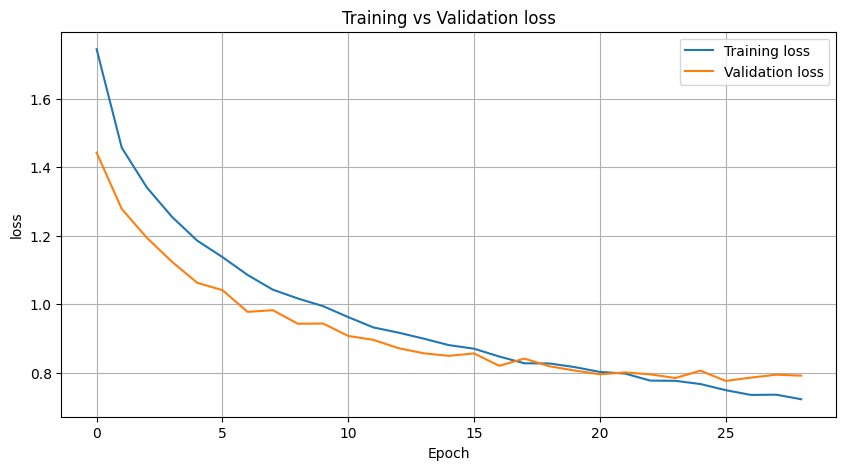

In [16]:
train_loss = (
    history.history['loss'] +
    history_continued.history['loss']
)

val_loss = (
    history.history['val_loss'] +
    history_continued.history['val_loss']
)

plt.figure(figsize=(10, 5))
plt.plot(train_loss, label='Training loss')
plt.plot(val_loss, label='Validation loss')

plt.title('Training vs Validation loss')
plt.xlabel('Epoch')
plt.ylabel('loss')
plt.legend()
plt.grid()
plt.show()

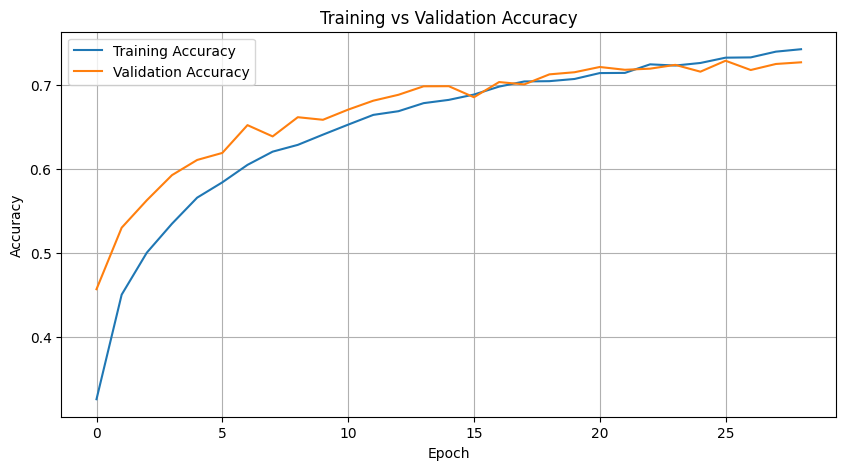

In [17]:
train_acc = (
    history.history['accuracy'] +
    history_continued.history['accuracy']
)

val_acc = (
    history.history['val_accuracy'] +
    history_continued.history['val_accuracy']
)

plt.figure(figsize=(10, 5))
plt.plot(train_acc, label='Training Accuracy')
plt.plot(val_acc, label='Validation Accuracy')

plt.title('Training vs Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid()
plt.show()

```markdown
## Confusion Matrix and Model Evaluation

To understand where our model is excelling and where it might be misclassifying specific emotions, we will:
1. Generate predictions on our unseen test dataset (`test_ds`).
2. Extract the true labels from the test dataset.
3. Compute a Confusion Matrix.
4. Visualize the results using a `seaborn` heatmap for clearer analysis.
```

In [18]:
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import os
from sklearn.metrics import confusion_matrix, classification_report

# 1. Extract true labels
y_true = []
for _, labels in test_ds:
    y_true.extend(np.argmax(labels.numpy(), axis=-1))
y_true = np.array(y_true)

# Dynamic retrieval of class names from the directory structure (sorted alphabetically as Keras does)
test_dir = '/content/dataset_emotion_detection/test'
class_names = sorted([d for d in os.listdir(test_dir) if os.path.isdir(os.path.join(test_dir, d))])
print("Class labels mapped to index:", {i: class_name for i, class_name in enumerate(class_names)})

Class labels mapped to index: {0: 'angry', 1: 'disgust', 2: 'fear', 3: 'happy', 4: 'neutral', 5: 'sad', 6: 'surprise'}


In [22]:
model.save('emotion_detection_vgg16.keras')
print("Model saved successfully!")

Model saved successfully!
